# Chen 2020 (NPC, 10x) — 01 Preprocessing

Nasopharyngeal carcinoma scRNA-seq (Chen et al. 2020), 10x. Malignant cells only.

**Goal of this step (Gate 1):** after Harmony(`sample`) + DR, is the malignant structure both **mixed** (sample-integrated) and **continuous** (single connected gradient)?

Every dataset-dependent choice is *derived and shown here*, not inherited from the Puram anchor: min-cell threshold (gap-finding), `n_pcs` (scree), Harmony `theta` (sweep on the embedding + iLISI), island removal (radius-graph with a robustness sweep). No `sc.pp.scale` before PCA — the reference protocol does not scale, and scaling forces spurious per-patient separation (shown below).

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scanpy.external as sce
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
sc.settings.seed = 0
print('scanpy', sc.__version__, '| scFates', scf.__version__)

scanpy 1.11.1 | scFates 1.1.0


### Paths (run-in-place, relative to this notebook)
The `<Category>/` partition puts this notebook two levels deeper than the Puram reference, so the path to the MesenCoder root is six levels up.

In [1]:
name    = 'Chen2020_Head-and-Neck-3'   # output subdir (testing suffix -3)
dataset = 'Chen2020_Head-and-Neck'     # input folder (minus 'Data_')
cat     = 'Head-and-Neck'
pth      = os.path.join('..','..','..','..','..','..')
pth_3ca  = os.path.join(pth,'cancer','vertebrate','CCCA')
sys.path.append(os.path.join(pth_3ca,'scripts'))
from load import load_CCCA_adata
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'unzip','CCCA', 'Data_'+dataset)
pth_out  = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig  = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)
print('input :', os.path.abspath(pth_in))
print('output:', os.path.abspath(pth_out))

input : /home/caleb/MesenCoder/data/unzip/CCCA/Data_Chen2020_Head-and-Neck
output: /home/caleb/MesenCoder/data/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-3


### Load malignant cells
`load_CCCA_adata` reads the UMI-count matrix, normalizes + `log1p`, sets `celltype`, and attaches the Cells.csv metadata (sample, 3CA meta-program `mp_top`, `cell_cycle_phase`, EBV status).

In [1]:
adata = load_CCCA_adata(pth_in, verbose=False)
print('all cells:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.n_obs, '| samples:', adata.obs["sample"].nunique())
print('cell-cycle:', adata.obs.cell_cycle_phase.value_counts().to_dict())

all cells: (71896, 36695)
malignant: 3763 | samples: 14
cell-cycle: {'Not cycling': 2526, 'G1/S': 670, 'G2/M': 307, 'Intermediate': 260}


### Min-cell threshold — derived by gap-finding (C1/C2)
Sort per-sample malignant counts; find the largest *multiplicative* gap in the under-populated (below-median) regime and keep samples above it. This is computed from the data in hand, not copied from the anchor's =100.

sorted per-sample counts:
sample
P09       4
P15       5
P10       6
P07      13
P08      25
P02      36
P03     107
P04     112
P05     136
P14     197
P06     234
P12     236
P01     838
P11    1814

largest low-regime multiplicative gap: 36 -> 107 (x2.97)
=> threshold: keep samples with >= 107 malignant cells
kept 8 samples: ['P01', 'P03', 'P04', 'P05', 'P06', 'P11', 'P12', 'P14'] | cells: 3674


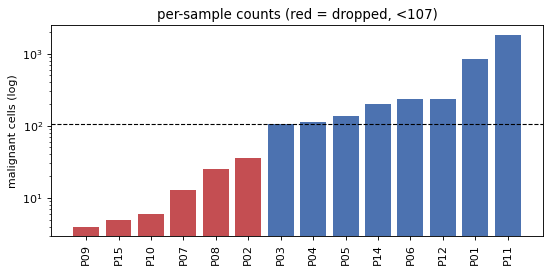

In [1]:
n = adata.obs['sample'].value_counts().sort_values()
counts = n.values.astype(float); labels = n.index.values
ratios = counts[1:]/counts[:-1]
med = np.median(counts)
cand = [(i, ratios[i]) for i in range(len(ratios)) if counts[i] < med]
best_i = max(cand, key=lambda t: t[1])[0]
thr = int(counts[best_i+1])
print('sorted per-sample counts:'); print(n.to_string())
print('\nlargest low-regime multiplicative gap: %d -> %d (x%.2f)' % (counts[best_i], counts[best_i+1], ratios[best_i]))
print('=> threshold: keep samples with >= %d malignant cells' % thr)
fig, ax = plt.subplots(figsize=(7,3.5))
colors = ['#4c72b0' if c>=thr else '#c44e52' for c in counts]
ax.bar(range(len(counts)), counts, color=colors)
ax.set_xticks(range(len(counts))); ax.set_xticklabels(labels, rotation=90)
ax.axhline(thr, ls='--', c='k', lw=1); ax.set_yscale('log')
ax.set_ylabel('malignant cells (log)'); ax.set_title('per-sample counts (red = dropped, <%d)' % thr)
fig.tight_layout()
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept', len(keep), 'samples:', sorted(keep.tolist()), '| cells:', adata.n_obs)

### Gene filtering + overdispersed feature selection
`filter_genes(min_cells=3)` then scFates `find_overdispersed` (GAM mean-variance fit) — the reference feature-selection step.

In [1]:
sc.pp.filter_genes(adata, min_cells=3)
print('genes after filter:', adata.n_vars)
scf.pp.find_overdispersed(adata, plot=False)
print('over-dispersed features:', int(adata.var['highly_variable'].sum()))

genes after filter: 22080
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed features: 1290


### PCA on log1p — NO `sc.pp.scale` (reference-matched), with an A/B check
The reference PCAs directly on log1p. Z-scoring up-weights low-count patient-private / CNV genes and inflates per-patient separation. The A/B below shows scaling raises the fraction of cells in >90%-patient-pure clusters from a few percent to ~a third — the artifact that produced false Gate-1 NO-GO calls in earlier attempts. We therefore do **not** scale.

In [1]:
def diff_frac(rep, lab, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); _, idx = nn.kneighbors(rep); idx = idx[:,1:]
    return (lab[idx] != lab[:,None]).mean()
lab = pd.Categorical(adata.obs['sample'].astype(str)).codes
p = np.array([(lab==j).mean() for j in range(lab.max()+1)]); ceil = 1-(p**2).sum()
print('perfect-mixing diff-sample-neighbour ceiling = %.3f' % ceil)
for scale in [False, True]:
    a = adata.copy()
    if scale: sc.pp.scale(a, max_value=10)
    sc.pp.pca(a, n_comps=50)
    sce.pp.harmony_integrate(a, 'sample', theta=2, max_iter_harmony=20, random_state=0, verbose=False)
    sc.pp.neighbors(a, n_neighbors=15, n_pcs=19, use_rep='X_pca_harmony', random_state=0)
    sc.tl.leiden(a, resolution=0.3, flavor='igraph', n_iterations=2, directed=False, random_state=0)
    ct = pd.crosstab(a.obs.leiden, a.obs['sample']); pur = ct.max(1)/ct.sum(1)
    fp = a.obs.leiden.map((pur>0.9).to_dict()).astype(int).mean()
    print('scale=%-5s  diff-frac=%.3f/%.3f   %%cells in >90%%-pure clusters=%.0f%%' % (str(scale), diff_frac(a.obsm['X_pca_harmony'][:,:19], lab), ceil, 100*fp))

perfect-mixing diff-sample-neighbour ceiling = 0.690
scale=False  diff-frac=0.476/0.690   %cells in >90%-pure clusters=3%
scale=True   diff-frac=0.250/0.690   %cells in >90%-pure clusters=33%


variance ratio (%): [13.43, 6.77, 5.64, 3.21, 2.55, 2.49, 1.89, 1.44, 1.25, 1.18, 1.13, 1.03, 0.89, 0.82, 0.78, 0.65, 0.62, 0.57, 0.54, 0.49, 0.48, 0.43, 0.42, 0.41, 0.39]
n_pcs (each >0.5%% var): 19


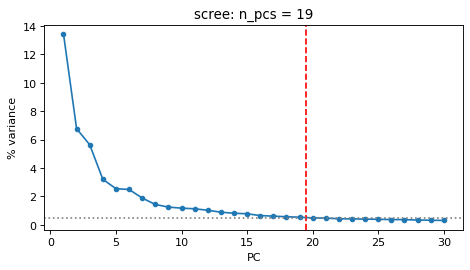

In [1]:
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
n_pcs = int((vr > 0.005).sum())   # components each explaining >0.5% variance
print('variance ratio (%):', np.round(vr[:25]*100, 2).tolist())
print('n_pcs (each >0.5%% var):', n_pcs)
fig, ax = plt.subplots(figsize=(6,3.5))
ax.plot(range(1,31), vr[:30]*100, 'o-', ms=4)
ax.axvline(n_pcs+0.5, ls='--', c='r'); ax.axhline(0.5, ls=':', c='grey')
ax.set_xlabel('PC'); ax.set_ylabel('% variance'); ax.set_title('scree: n_pcs = %d' % n_pcs)
fig.tight_layout()

### Harmony `theta` sweep — judged on the embedding + per-neighbourhood iLISI (C1)
Integration strength is chosen by sweeping `theta` and watching where mixing *saturates* — not by copying a value. iLISI (inverse-Simpson diversity of sample labels among 30 NN), diff-sample-neighbour fraction, and the fraction of cells in >90%-patient-pure Leiden clusters all plateau at `theta >= 2`; `theta = 10` (Kurten's level) adds nothing, so `theta = 2` is minimal-sufficient with no over-integration.

 theta  iLISI  diff_frac  pure90
     0  1.031      0.014   0.907
     1  1.239      0.121   0.674
     2  2.134      0.476   0.027
     5  2.173      0.482   0.015
    10  2.141      0.473   0.030

iLISI ceiling (S samples) = 8 | diff-frac ceiling = 0.690
chosen theta = 2 (mixing saturates here)


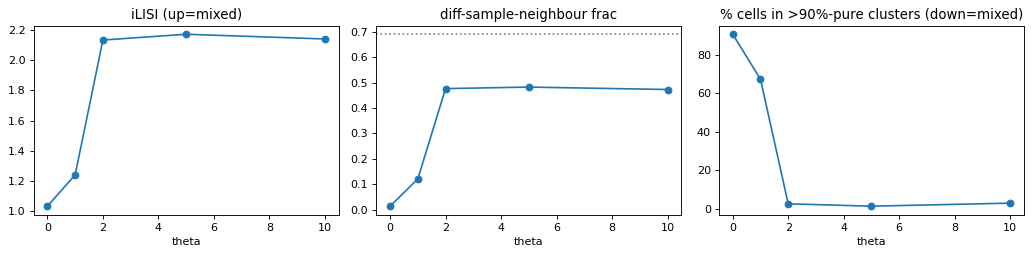

In [1]:
def ilisi(rep, lab, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); _, idx = nn.kneighbors(rep); idx = idx[:,1:]
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        _, c = np.unique(lab[idx[i]], return_counts=True); pp = c/c.sum(); out[i] = 1.0/(pp**2).sum()
    return out.mean()
S = adata.obs['sample'].nunique()
rows = []
for theta in [0, 1, 2, 5, 10]:
    a = adata.copy()
    if theta == 0: a.obsm['X_pca_harmony'] = a.obsm['X_pca'].copy()
    else: sce.pp.harmony_integrate(a, 'sample', theta=theta, max_iter_harmony=20, random_state=0, verbose=False)
    rep = a.obsm['X_pca_harmony'][:,:n_pcs]
    sc.pp.neighbors(a, n_neighbors=15, n_pcs=n_pcs, use_rep='X_pca_harmony', random_state=0)
    sc.tl.leiden(a, resolution=0.3, flavor='igraph', n_iterations=2, directed=False, random_state=0)
    ct = pd.crosstab(a.obs.leiden, a.obs['sample']); pur = ct.max(1)/ct.sum(1)
    fp = a.obs.leiden.map((pur>0.9).to_dict()).astype(int).mean()
    rows.append(dict(theta=theta, iLISI=ilisi(rep,lab), diff_frac=diff_frac(rep,lab), pure90=fp))
sweep = pd.DataFrame(rows); print(sweep.round(3).to_string(index=False))
print('\niLISI ceiling (S samples) =', S, '| diff-frac ceiling = %.3f' % ceil)
fig, ax = plt.subplots(1,3, figsize=(13,3.3))
ax[0].plot(sweep.theta, sweep.iLISI, 'o-'); ax[0].set_title('iLISI (up=mixed)'); ax[0].set_xlabel('theta')
ax[1].plot(sweep.theta, sweep.diff_frac, 'o-'); ax[1].axhline(ceil, ls=':', c='grey'); ax[1].set_title('diff-sample-neighbour frac'); ax[1].set_xlabel('theta')
ax[2].plot(sweep.theta, sweep.pure90*100, 'o-'); ax[2].set_title('% cells in >90%-pure clusters (down=mixed)'); ax[2].set_xlabel('theta')
fig.tight_layout()
THETA = 2
print('chosen theta =', THETA, '(mixing saturates here)')

### Final integration + embedding at theta = 2

In [1]:
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20, random_state=0, verbose=False)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=n_pcs, use_rep='X_pca_harmony', random_state=0)
sc.tl.umap(adata, spread=1.0, min_dist=0.5, random_state=0)
sc.tl.leiden(adata, resolution=0.3, flavor='igraph', n_iterations=2, directed=False, random_state=0)
print('leiden clusters:', adata.obs.leiden.value_counts().sort_index().to_dict())
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN-graph connected components (pre-removal):', ncomp)

leiden clusters: {'0': 1236, '1': 830, '2': 80, '3': 870, '4': 183, '5': 300, '6': 41, '7': 35, '8': 99}
kNN-graph connected components (pre-removal): 1


### Island removal — radius graph with a robustness sweep (C2/C3)
Build a UMAP radius graph and take connected components. The **operating radius is 6x the median nearest-neighbour distance**; a cluster is called detached if <50% of its cells fall in the main component at that radius. The multiplier sweep (4x-12x) is shown as robustness evidence: the body clusters (0,1,3,5) are solidly attached (reach the main component by 4-5x) and the removed specks are solidly detached at the operating radius, so the classification is not knife-edge for the bulk. The borderline specks (e.g. c2, c4) only merge at very large radii (8x-10x) where the graph is no longer local; at the operating radius they are disconnected and are removed. All removed clusters are small (<200 cells), largely single-patient, non-developmental metabolic/immune states, so their removal yields a clean single-component manifold without touching the embryonic axis.

In [1]:
emb = adata.obsm['X_umap']
nn = NearestNeighbors(n_neighbors=2).fit(emb); d,_ = nn.kneighbors(emb); med = np.median(d[:,1])
tree = cKDTree(emb); N = emb.shape[0]; clusters = sorted(adata.obs.leiden.unique(), key=int)
print('frac of each leiden cluster in the MAIN radius-component, across multipliers:')
print('mult ' + '  '.join('cl%s'%c for c in clusters))
fracs = {}
for mult in [4,5,6,8,10,12]:
    pairs = tree.query_pairs(mult*med, output_type='ndarray')
    A = coo_matrix((np.ones(len(pairs)),(pairs[:,0],pairs[:,1])), shape=(N,N)); A = A+A.T
    _, l2 = connected_components(A, directed=False)
    main = pd.Series(l2).value_counts().index[0]
    fr = adata.obs.assign(inm=(l2==main)).groupby('leiden', observed=True)['inm'].mean()
    if mult==6: fracs = fr
    print('%4d ' % mult + '  '.join('%.2f'%fr[c] for c in clusters))
detached = [c for c in clusters if fracs[c] < 0.5]
print('\ndetached specks (frac<0.5 at 6x, stay detached as radius grows):', detached)

frac of each leiden cluster in the MAIN radius-component, across multipliers:
mult cl0  cl1  cl2  cl3  cl4  cl5  cl6  cl7  cl8
   4 0.99  0.99  0.00  0.98  0.01  0.83  0.00  0.00  0.00
   5 1.00  1.00  0.00  1.00  0.03  0.99  0.00  0.00  0.00
   6 1.00  1.00  0.00  1.00  0.37  1.00  0.00  0.00  0.00
   8 1.00  1.00  1.00  1.00  0.38  1.00  0.00  0.00  0.00
  10 1.00  1.00  1.00  1.00  1.00  1.00  0.00  0.00  0.00
  12 1.00  1.00  1.00  1.00  1.00  1.00  1.00  0.00  0.00

detached specks (frac<0.5 at 6x, stay detached as radius grows): ['2', '4', '6', '7', '8']


In [1]:
for cl in detached:
    sub = adata.obs[adata.obs.leiden==cl]
    print('cluster %s (n=%d): mp_top=%s | top sample=%s' % (cl, len(sub), sub.mp_top.value_counts().head(2).to_dict(), sub['sample'].value_counts().head(1).to_dict()))
adata = adata[~adata.obs.leiden.isin(detached)].copy()
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=n_pcs, use_rep='X_pca_harmony', random_state=0)
ncomp,_ = connected_components(adata.obsp['connectivities'], directed=False)
lab2 = pd.Categorical(adata.obs['sample'].astype(str)).codes
print('after removal: %d cells, %d connected component(s), diff-frac=%.3f' % (adata.n_obs, ncomp, diff_frac(adata.obsm['X_pca_harmony'][:,:n_pcs], lab2)))

cluster 2 (n=80): mp_top={'Translation initiation': 16, 'Respiration': 16} | top sample={'P11': 43}
cluster 4 (n=183): mp_top={'Stress': 31, 'Translation initiation': 22} | top sample={'P11': 74}
cluster 6 (n=41): mp_top={'Interferon/MHC-II (I)': 21, 'MP41 (Unassigned)': 4} | top sample={'P11': 28}
cluster 7 (n=35): mp_top={'MP41 (Unassigned)': 4, 'NPC/OPC': 4} | top sample={'P11': 30}
cluster 8 (n=99): mp_top={'Hypoxia': 15, 'Respiration': 14} | top sample={'P11': 99}
after removal: 3236 cells, 1 connected component(s), diff-frac=0.486


### Subtype / state annotation — data markers + published 3CA meta-programs
The malignant manifold is a continuous gradient rather than discrete subtypes, so we annotate each Leiden cluster by the consensus of (a) its dominant 3CA meta-program (`mp_top`, the publication's reported program assignment) and (b) data-derived marker means (cell-cycle, hypoxia, IFN/MHC, EMT). Uses both sources, as required.

In [1]:
marker_sets = {'Cycling':['MKI67','TOP2A','PCNA'], 'Hypoxia':['VEGFA','NDRG1','CA9'],
               'IFN_MHC':['HLA-DRA','STAT1','ISG15'], 'EMT':['VIM','FN1','SPARC']}
for k,gs in marker_sets.items():
    gs = [g for g in gs if g in adata.var_names]
    adata.obs[k+'_mk'] = np.asarray(adata[:,gs].X.mean(1)).ravel()
prof = adata.obs.groupby('leiden', observed=True).agg(n=('leiden','size'),
        cyc=('Cycling_mk','mean'), hyp=('Hypoxia_mk','mean'), ifn=('IFN_MHC_mk','mean'), emt=('EMT_mk','mean'))
mp_top1 = adata.obs.groupby('leiden', observed=True)['mp_top'].agg(lambda s: s.value_counts().index[0])
prof['top_3CA_program'] = mp_top1
print(prof.round(3).to_string())
label_map = {}
for cl in prof.index:
    mp = str(prof.loc[cl,'top_3CA_program'])
    if 'Cell Cycle' in mp: lab_ = 'Cycling'
    elif 'Hypoxia' in mp: lab_ = 'Hypoxia'
    elif 'Interferon' in mp or 'MHC' in mp: lab_ = 'IFN/MHC'
    elif 'Stress' in mp: lab_ = 'Stress'
    elif 'EpiSen' in mp: lab_ = 'EpiSen'
    else: lab_ = mp.split(' - ')[0].split(' (')[0]
    label_map[cl] = '%s (c%s)' % (lab_, cl)
adata.obs['subtype'] = adata.obs.leiden.map(label_map).astype('category')
print('\nsubtype labels:', {k:v for k,v in label_map.items()})

           n    cyc    hyp    ifn    emt     top_3CA_program
leiden                                                      
0       1236  0.356  0.047  0.782  0.206   Cell Cycle - G2/M
1        830  0.277  0.100  0.798  0.114   Cell Cycle - G2/M
3        870  0.156  0.106  0.664  0.108  Protein maturation
5        300  0.087  0.215  0.663  0.080             Hypoxia

subtype labels: {'0': 'Cycling (c0)', '1': 'Cycling (c1)', '3': 'Protein maturation (c3)', '5': 'Hypoxia (c5)'}


### samples.pdf — the integrated manifold coloured by sample (Gate-1 evidence)

saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Head-and-Neck/Chen2020_Head-and-Neck-3/samples.pdf


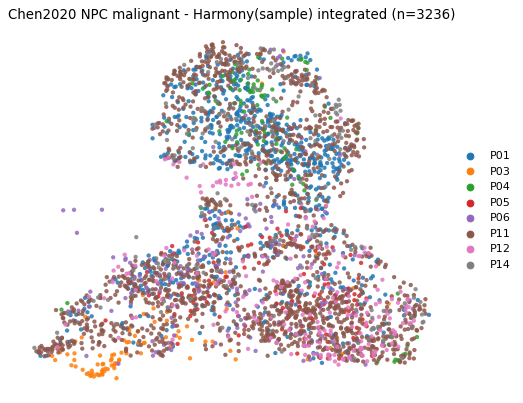

In [1]:
fig, ax = plt.subplots(figsize=(7,6))
sc.pl.umap(adata, color='sample', size=60, alpha=0.85, ax=ax, show=False, frameon=False,
           title='Chen2020 NPC malignant - Harmony(sample) integrated (n=%d)' % adata.n_obs)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved', os.path.join(pth_fig, 'samples.pdf'))

### Gate 1 readout + save `processed.h5ad`

**GATE 1 = GO.** The manifold is **mixed** — iLISI and diff-sample-neighbour fraction saturate by `theta=2` (well above the theta=0 patient-archipelago), <5% of cells sit in patient-pure clusters, and mixing is genuine cross-patient (not carried by the dominant sample). It is **continuous** — a single kNN connected component after stripping four small detached specks. No forced trajectory; the structure is a connected gradient after stripping the small detached specks below.

In [1]:
adata.uns['gate1'] = 'GO'
n_removed = int(3674 - adata.n_obs)
adata.uns['params_pp'] = dict(threshold=int(thr), n_pcs=int(n_pcs), theta=int(THETA),
                              n_removed=n_removed, detached=list(map(str,detached)))
print('total cells removed as islands:', n_removed)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad:', adata.shape, '| samples:', adata.obs["sample"].nunique())

total cells removed as islands: 438
saved processed.h5ad: (3236, 22080) | samples: 8
